In [1]:
import numpy as np
import RandomTilings as RT
from numba import njit,prange
from time import perf_counter as time
from tqdm import trange
import matplotlib.pyplot as plt
from gc import collect

# Copies

In [2]:
@njit("(float64, float64, float64, float64, int32, int32, int32, int32)",cache=True,inline="always")
def update(w,x,y,z,ew,ex,ey,ez):
    overflow = False
    if w==0:
        w        = 1
        ew      += 1
        overflow = True
    elif 1/w==0:
        w        = 1
        ew      -= 1
        overflow = True
    if x==0:
        x        = 1
        ex      += 1
        overflow = True
    elif 1/x==0:
        x        = 1
        ex      -= 1
        overflow = True
    if y==0:
        y        = 1
        ey      += 1
        overflow = True
    elif 1/y==0:
        y        = 1
        ey      -= 1
        overflow = True

    if z==0:
        z        = 1
        ez      += 1
        overflow = True
    elif 1/z==0:
        z        = 1
        ez      -= 1
        overflow = True

    Ixy = ex+ey
    Iwz = ew+ez

    if Ixy>Iwz:
        tmp = w*z
        if tmp == 0:
           return 1/w,1,1,1/z,-ew,ey-Iwz-1,ex-Iwz-1,-ez,True
        elif 1/tmp ==0:
            return 1/w,1,1,1/z,-ew,ey-Iwz+1,ex-Iwz+1,-ez,True
        else:
            return 1/w,y/tmp,x/tmp,1/z,-ew,ey-Iwz,ex-Iwz,-ez,overflow
    elif Ixy<Iwz:
        tmp = x*y
        if tmp == 0:
            return 1,1/x,1/y,1,ez-Ixy-1,-ex,-ey,ew-Ixy-1,True
        elif 1/tmp ==0:
            return 1,1/x,1/y,1,ez-Ixy+1,-ex,-ey,ew-Ixy+1,True
        else:
            return z/tmp,1/x,1/y,w/tmp,ez-Ixy,-ex,-ey,ew-Ixy,overflow
    else:
        tmp = z*w+x*y
        if tmp == 0:
            return 1, 1, 1, 1, ez-Ixy-1,ey-Ixy-1,ex-Ixy-1,ew-Ixy-1,True
        elif 1/tmp == 0:
            return 1, 1, 1, 1, ez-Ixy+1,ey-Ixy+1,ex-Ixy+1,ew-Ixy+1,True
        else:
            return z/tmp, y/tmp, x/tmp, w/tmp, ez-Ixy,ey-Ixy,ex-Ixy,ew-Ixy,overflow

@njit("(float64, float64, float64, float64, int32, int32, int32, int32)",cache=True,inline="always")
def comp_prop(w,x,y,z,ew,ex,ey,ez):
    Ixy = ex+ey
    Iwz = ew+ez
    if Ixy>Iwz:
        return 1.,False
    elif Ixy < Iwz:
        return 0.,False
    tmp = (w*z+x*y)
    if tmp == 0 or 1/tmp == 0:
        return 1/2, True
    else:
        return w*z/(w*z+x*y),False

@njit("(Array(float64, 2, 'C', False, aligned=True),Array(int32, 2, 'C', False, aligned=True))",cache=True,parallel=True)
def reduce_weight(W,E):
    K = W.shape[0]//2
    C = W.copy()+(W==0)
    E+= 1*(W == 0)
    overflow = False
    for k in range(K-1):
        for m in prange(K-k):
            for n in prange(K-k):
                I00,I01,I10,I11 = k+2*m,k+2*n,k+2*m+1,k+2*n+1
                w ,x ,y ,z  = C[I00,I01],C[I00,I11],C[I10,I01],C[I10,I11]
                ew,ex,ey,ez = E[I00,I01],E[I00,I11],E[I10,I01],E[I10,I11]

                w,x,y,z,ew,ex,ey,ez,of = update(w,x,y,z,ew,ex,ey,ez)
                C[I00,I01],C[I00,I11],C[I10,I01],C[I10,I11] = w,x,y,z
                E[I00,I01],E[I00,I11],E[I10,I01],E[I10,I11] = ew,ex,ey,ez
                overflow = overflow or of
    return C,E,overflow


#@njit("(Array(float64, 2, 'C', False, aligned=True),Array(int32, 2, 'C', False, aligned=True))",
      #cache=True,parallel=True)
def shuffling0(C0,E0):
    C = C0.copy()
    E = E0.copy()
    N = C.shape[0]
    M = np.zeros((N,N),dtype=np.int8)
    overflow = False

    T = 0

    # initiate
    A = N//2-1
    w,x,y,z     = C[A,A],C[A,A+1],C[A+1,A],C[A+1,A+1]
    ew,ex,ey,ez = E[A,A],E[A,A+1],E[A+1,A],E[A+1,A+1]
    prob,of = comp_prop(w,x,y,z,ew,ex,ey,ez)
    overflow = overflow or of
    if np.random.random()<prob:
        M[A,A],M[A+1,A+1]= 1,1
        M[A,A+1],M[A+1,A]= 0,0
    else:
        M[A,A],M[A+1,A+1]= 0,0
        M[A,A+1],M[A+1,A]= 1,1

    for k in range(1,N//2):
        A = N//2-1-k   

        # destruction + flip (+ reconstruct)
        for m in range(k+1):
            for n in range(k+1):
                I00,I01,I10,I11 = A+2*m,A+2*n,A+2*m+1,A+2*n+1
                # reconstruct
                w,x,y,z     = C[I00,I01],C[I00,I11],C[I10,I01],C[I10,I11]
                ew,ex,ey,ez = E[I00,I01],E[I00,I11],E[I10,I01],E[I10,I11]
                
                w,x,y,z,ew,ex,ey,ez,of = update(w,x,y,z,ew,ex,ey,ez)
                overflow = overflow or of
                C[I00,I01],C[I00,I11],C[I10,I01],C[I10,I11] = w,x,y,z
                E[I00,I01],E[I00,I11],E[I10,I01],E[I10,I11] = ew,ex,ey,ez

        t1 = time()
        for m in range(k+1):
            for n in range(k+1):
                # destruction + flip
                tmp = M[I00,I01]+M[I10,I01]+M[I00,I11]+M[I10,I11]
                if tmp>1:
                    M[I00,I01],M[I10,I01],M[I00,I11],M[I10,I11]=0,0,0,0
                elif tmp == 1:
                    M[I00,I01],M[I10,I11]=M[I10,I11],M[I00,I01]
                    M[I00,I11],M[I10,I01]=M[I10,I01],M[I00,I11]
        

        for m in range(k+1):
            for n in range(k+1):
                # start checking for neighbor
                A = N//2-1-k  
                I00,I01,I10,I11 = A+2*m,A+2*n,A+2*m+1,A+2*n+1
                
                if M[I00,I01]+M[I10,I01]+M[I00,I11]+M[I10,I11]>0:
                    no_neighbor = False
                else:
                    if n==0:
                        tmp_w = True
                        tmp_e = (M[I00,I11+1]+M[I10,I11+1])==0
                    elif n==k:
                        tmp_w = (M[I00,I01-1]+M[I10,I01-1])==0
                        tmp_e = True
                    else:
                        tmp_w = (M[I00,I01-1]+M[I10,I01-1])==0
                        tmp_e = (M[I00,I11+1]+M[I10,I11+1])==0

                    if m==0:
                        tmp_n = True
                        tmp_s = (M[I10+1,I01]+M[I10+1,I11])==0
                    elif m==k:
                        tmp_n = (M[I00-1,I01]+M[I00-1,I11])==0
                        tmp_s = True
                    else:
                        tmp_n = (M[I00-1,I01]+M[I00-1,I11])==0
                        tmp_s = (M[I00+1,I01]+M[I00+1,I11])==0
                    no_neighbor = tmp_s and tmp_e and tmp_w and tmp_n
                # end checking for neighbor

                if no_neighbor:
                    w,x,y,z     = C[I00,I01],C[I00,I11],C[I10,I01],C[I10,I11]
                    ew,ex,ey,ez = E[I00,I01],E[I00,I11],E[I10,I01],E[I10,I11]
                    prob,of  = comp_prop(w,x,y,z,ew,ex,ey,ez)
                    overflow = overflow or of

                    if np.random.random()<prob:
                        M[I00,I01],M[I10,I11]= 1,1
                        M[I00,I11],M[I10,I01]= 0,0
                    else:
                        M[I00,I01],M[I10,I11]= 0,0
                        M[I00,I11],M[I10,I01]= 1,1
        T += time()-t1
    print(T)
    return M,overflow

In [21]:


# In the old matrix, each code occupies these cells of a 2 x 2 block:
# 0: none, 1: upper left, 2: upper right, 3: lower left,
# 4: lower right, 5: main diagonal, 6: other diagonal.
_TOP_LEFT = np.array([0, 1, 0, 0, 0, 1, 0], dtype=np.int8)
_TOP_RIGHT = np.array([0, 0, 1, 0, 0, 0, 1], dtype=np.int8)
_BOTTOM_LEFT = np.array([0, 0, 0, 1, 0, 0, 1], dtype=np.int8)
_BOTTOM_RIGHT = np.array([0, 0, 0, 0, 1, 1, 0], dtype=np.int8)

# Whether a block has an occupied cell on a given edge.
_HAS_RIGHT = np.array([0, 0, 1, 0, 1, 1, 1], dtype=np.int8)
_HAS_BOTTOM = np.array([0, 0, 0, 1, 1, 1, 1], dtype=np.int8)


def DF(w, x, y, z):
    """Destroy and flip one new block from four old neighboring blocks."""
    a = _BOTTOM_RIGHT[w]
    b = _BOTTOM_LEFT[x]
    c = _TOP_RIGHT[y]
    d = _TOP_LEFT[z]
    if a + b + c + d != 1:
        return 0
    if a:
        return 4
    if b:
        return 3
    if c:
        return 2
    return 1


DF_Table = np.empty((7, 7, 7, 7), dtype=np.int8)
for _w in range(7):
    for _x in range(7):
        for _y in range(7):
            for _z in range(7):
                DF_Table[_w, _x, _y, _z] = DF(_w, _x, _y, _z)


@njit(cache=True)
def cmpr_shuffling(C0, E0):
    """Return the tiling as an N x N array of codes 0..6, plus overflow."""
    C = C0.copy()
    E = E0.copy()
    N = C.shape[0] // 2
    M0 = np.zeros((N, N), dtype=np.int8)
    M1 = np.zeros((N, N), dtype=np.int8)
    overflow = False

    A = N - 1
    w, x, y, z = C[A, A], C[A, A + 1], C[A + 1, A], C[A + 1, A + 1]
    ew, ex, ey, ez = E[A, A], E[A, A + 1], E[A + 1, A], E[A + 1, A + 1]
    prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
    overflow = overflow or of
    if N % 2 == 0:
        Mold = M1
    else:
        Mold = M0
    if np.random.random() < prob:
        Mold[0, 0] = 5
    else:
        Mold[0, 0] = 6

    # Each stage changes the parity of the block grid. Reuse two buffers.
    for k in range(1, N):
        if (k + N) % 2 == 0:
            Mnew = M1
        else:
            Mnew = M0
        A = N - 1 - k

        # Top-left corner.
        i = A
        j = A
        w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
        ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
        w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
        overflow = overflow or of
        C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
        E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
        Mnew[0, 0] = DF_Table[0, 0, 0, Mold[0, 0]]
        if Mnew[0, 0] == 0:
            prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
            overflow = overflow or of
            Mnew[0, 0] = 5 if np.random.random() < prob else 6

        # Top row and left column in one loop.
        for t in range(1, k + 1):
            i = A
            j = A + 2 * t
            w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
            ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
            w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
            overflow = overflow or of
            C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
            E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
            Mnew[0, t] = DF_Table[0, 0, Mold[0, t - 1], Mold[0, t]]
            if Mnew[0, t] == 0 and not _HAS_RIGHT[Mnew[0, t - 1]]:
                prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
                overflow = overflow or of
                Mnew[0, t] = 5 if np.random.random() < prob else 6

            i = A + 2 * t
            j = A
            w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
            ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
            w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
            overflow = overflow or of
            C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
            E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
            Mnew[t, 0] = DF_Table[0, Mold[t - 1, 0], 0, Mold[t, 0]]
            if Mnew[t, 0] == 0 and not _HAS_BOTTOM[Mnew[t - 1, 0]]:
                prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
                overflow = overflow or of
                Mnew[t, 0] = 5 if np.random.random() < prob else 6

        # Remaining blocks. Mold's unused bottom row and right column are zero.
        for m in range(1, k + 1):
            i = A + 2 * m
            for n in range(1, k + 1):
                j = A + 2 * n
                w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
                ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
                w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
                overflow = overflow or of
                C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
                E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
                Mnew[m, n] = DF_Table[
                    Mold[m - 1, n - 1], Mold[m - 1, n],
                    Mold[m, n - 1], Mold[m, n]
                ]
                if (Mnew[m, n] == 0
                        and not _HAS_RIGHT[Mnew[m, n - 1]]
                        and not _HAS_BOTTOM[Mnew[m - 1, n]]):
                    prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
                    overflow = overflow or of
                    Mnew[m, n] = 5 if np.random.random() < prob else 6

        Mold = Mnew

    return Mold, overflow


def expand_blocks(M):
    """Convert an N x N code array back to the old 2N x 2N binary array."""
    N = M.shape[0]
    out = np.empty((2 * N, 2 * N), dtype=np.int8)
    out[0::2, 0::2] = _TOP_LEFT[M]
    out[0::2, 1::2] = _TOP_RIGHT[M]
    out[1::2, 0::2] = _BOTTOM_LEFT[M]
    out[1::2, 1::2] = _BOTTOM_RIGHT[M]
    return out


In [43]:
"""Compact and binary random-tiling shuffling with matching loop structure.

Input C0 and E0 are the same 2N x 2N arrays used by the original shuffling
routine. The result is an N x N array of block codes 0..6 and an overflow flag.
Numba is used when installed; otherwise the same functions run in Python.
Creation visits top and left edges together, so a fixed random seed need not
produce the same sample as the original row-major implementation.
"""

import numpy as np

try:
    from numba import njit
except ImportError:
    def njit(*args, **kwargs):
        return lambda function: function


@njit(cache=True, inline="always")
def update(w,x,y,z,ew,ex,ey,ez):
    overflow = False
    if w==0:
        w        = 1
        ew      += 1
        overflow = True
    elif 1/w==0:
        w        = 1
        ew      -= 1
        overflow = True
    if x==0:
        x        = 1
        ex      += 1
        overflow = True
    elif 1/x==0:
        x        = 1
        ex      -= 1
        overflow = True
    if y==0:
        y        = 1
        ey      += 1
        overflow = True
    elif 1/y==0:
        y        = 1
        ey      -= 1
        overflow = True

    if z==0:
        z        = 1
        ez      += 1
        overflow = True
    elif 1/z==0:
        z        = 1
        ez      -= 1
        overflow = True

    Ixy = ex+ey
    Iwz = ew+ez

    if Ixy>Iwz:
        tmp = w*z
        if tmp == 0:
           return 1/w,1,1,1/z,-ew,ey-Iwz-1,ex-Iwz-1,-ez,True
        elif 1/tmp ==0:
            return 1/w,1,1,1/z,-ew,ey-Iwz+1,ex-Iwz+1,-ez,True
        else:
            return 1/w,y/tmp,x/tmp,1/z,-ew,ey-Iwz,ex-Iwz,-ez,overflow
    elif Ixy<Iwz:
        tmp = x*y
        if tmp == 0:
            return 1,1/x,1/y,1,ez-Ixy-1,-ex,-ey,ew-Ixy-1,True
        elif 1/tmp ==0:
            return 1,1/x,1/y,1,ez-Ixy+1,-ex,-ey,ew-Ixy+1,True
        else:
            return z/tmp,1/x,1/y,w/tmp,ez-Ixy,-ex,-ey,ew-Ixy,overflow
    else:
        tmp = z*w+x*y
        if tmp == 0:
            return 1, 1, 1, 1, ez-Ixy-1,ey-Ixy-1,ex-Ixy-1,ew-Ixy-1,True
        elif 1/tmp == 0:
            return 1, 1, 1, 1, ez-Ixy+1,ey-Ixy+1,ex-Ixy+1,ew-Ixy+1,True
        else:
            return z/tmp, y/tmp, x/tmp, w/tmp, ez-Ixy,ey-Ixy,ex-Ixy,ew-Ixy,overflow

@njit(cache=True, inline="always")
def comp_prop(w,x,y,z,ew,ex,ey,ez):
    Ixy = ex+ey
    Iwz = ew+ez
    if Ixy>Iwz:
        return 1.,False
    elif Ixy < Iwz:
        return 0.,False
    tmp = (w*z+x*y)
    if tmp == 0 or 1/tmp == 0:
        return 1/2, True
    else:
        return w*z/(w*z+x*y),False


# In the old matrix, each code occupies these cells of a 2 x 2 block:
# 0: none, 1: upper left, 2: upper right, 3: lower left,
# 4: lower right, 5: main diagonal, 6: other diagonal.
_TOP_LEFT = np.array([0, 1, 0, 0, 0, 1, 0], dtype=np.int8)
_TOP_RIGHT = np.array([0, 0, 1, 0, 0, 0, 1], dtype=np.int8)
_BOTTOM_LEFT = np.array([0, 0, 0, 1, 0, 0, 1], dtype=np.int8)
_BOTTOM_RIGHT = np.array([0, 0, 0, 0, 1, 1, 0], dtype=np.int8)

# Whether a block has an occupied cell on a given edge.
_HAS_RIGHT = np.array([0, 0, 1, 0, 1, 1, 1], dtype=np.int8)
_HAS_BOTTOM = np.array([0, 0, 0, 1, 1, 1, 1], dtype=np.int8)


def DF(w, x, y, z):
    """Destroy and flip one new block from four old neighboring blocks."""
    a = _BOTTOM_RIGHT[w]
    b = _BOTTOM_LEFT[x]
    c = _TOP_RIGHT[y]
    d = _TOP_LEFT[z]
    if a + b + c + d != 1:
        return 0
    if a:
        return 4
    if b:
        return 3
    if c:
        return 2
    return 1


DF_Table = np.empty((7, 7, 7, 7), dtype=np.int8)
for _w in range(7):
    for _x in range(7):
        for _y in range(7):
            for _z in range(7):
                DF_Table[_w, _x, _y, _z] = DF(_w, _x, _y, _z)


@njit(cache=True)
def cmpr_shuffling(C0, E0):
    """Return the tiling as an N x N array of codes 0..6, plus overflow."""
    C = C0.copy()
    E = E0.copy()
    N = C.shape[0] // 2
    M0 = np.zeros((N, N), dtype=np.int8)
    M1 = np.zeros((N, N), dtype=np.int8)
    overflow = False

    A = N - 1
    w, x, y, z = C[A, A], C[A, A + 1], C[A + 1, A], C[A + 1, A + 1]
    ew, ex, ey, ez = E[A, A], E[A, A + 1], E[A + 1, A], E[A + 1, A + 1]
    prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
    overflow = overflow or of
    if N % 2 == 0:
        Mold = M1
    else:
        Mold = M0
    if np.random.random() < prob:
        Mold[0, 0] = 5
    else:
        Mold[0, 0] = 6

    # Each stage changes the parity of the block grid. Reuse two buffers.
    for k in range(1, N):
        if (k + N) % 2 == 0:
            Mnew = M1
        else:
            Mnew = M0
        A = N - 1 - k

        # Top-left corner.
        i = A
        j = A
        w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
        ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
        w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
        overflow = overflow or of
        C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
        E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
        Mnew[0, 0] = DF_Table[0, 0, 0, Mold[0, 0]]
        if Mnew[0, 0] == 0:
            prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
            overflow = overflow or of
            Mnew[0, 0] = 5 if np.random.random() < prob else 6

        # Top row and left column in one loop.
        for t in range(1, k + 1):
            i = A
            j = A + 2 * t
            w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
            ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
            w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
            overflow = overflow or of
            C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
            E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
            Mnew[0, t] = DF_Table[0, 0, Mold[0, t - 1], Mold[0, t]]
            if Mnew[0, t] == 0 and not _HAS_RIGHT[Mnew[0, t - 1]]:
                prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
                overflow = overflow or of
                Mnew[0, t] = 5 if np.random.random() < prob else 6

            i = A + 2 * t
            j = A
            w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
            ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
            w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
            overflow = overflow or of
            C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
            E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
            Mnew[t, 0] = DF_Table[0, Mold[t - 1, 0], 0, Mold[t, 0]]
            if Mnew[t, 0] == 0 and not _HAS_BOTTOM[Mnew[t - 1, 0]]:
                prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
                overflow = overflow or of
                Mnew[t, 0] = 5 if np.random.random() < prob else 6

        # Remaining blocks. Mold's unused bottom row and right column are zero.
        for m in range(1, k + 1):
            i = A + 2 * m
            for n in range(1, k + 1):
                j = A + 2 * n
                w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
                ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
                w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
                overflow = overflow or of
                C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
                E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
                Mnew[m, n] = DF_Table[
                    Mold[m - 1, n - 1], Mold[m - 1, n],
                    Mold[m, n - 1], Mold[m, n]
                ]
                if (Mnew[m, n] == 0
                        and not _HAS_RIGHT[Mnew[m, n - 1]]
                        and not _HAS_BOTTOM[Mnew[m - 1, n]]):
                    prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
                    overflow = overflow or of
                    Mnew[m, n] = 5 if np.random.random() < prob else 6

        Mold = Mnew

    return Mold, overflow


@njit(cache=True)
def binary_shuffling_fused(C0, E0):
    """Return the tiling as a 2N x 2N binary array, plus overflow.

    Uses the same corner, edge, and interior traversal as cmpr_shuffling.
    """
    C = C0.copy()
    E = E0.copy()
    N = C.shape[0] // 2
    M = np.zeros((2 * N, 2 * N), dtype=np.int8)
    overflow = False

    A = N - 1
    w, x, y, z = C[A, A], C[A, A + 1], C[A + 1, A], C[A + 1, A + 1]
    ew, ex, ey, ez = E[A, A], E[A, A + 1], E[A + 1, A], E[A + 1, A + 1]
    prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
    overflow = overflow or of
    if np.random.random() < prob:
        M[A, A], M[A, A + 1], M[A + 1, A], M[A + 1, A + 1] = 1, 0, 0, 1
    else:
        M[A, A], M[A, A + 1], M[A + 1, A], M[A + 1, A + 1] = 0, 1, 1, 0

    for k in range(1, N):
        A = N - 1 - k

        # Top-left corner.
        i = A
        j = A
        w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
        ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
        w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
        overflow = overflow or of
        C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
        E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
        count = M[i, j] + M[i, j + 1] + M[i + 1, j] + M[i + 1, j + 1]
        if count > 1:
            M[i, j], M[i, j + 1], M[i + 1, j], M[i + 1, j + 1] = 0, 0, 0, 0
        elif count == 1:
            M[i, j], M[i + 1, j + 1] = M[i + 1, j + 1], M[i, j]
            M[i, j + 1], M[i + 1, j] = M[i + 1, j], M[i, j + 1]
        if count != 1:
            prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
            overflow = overflow or of
            if np.random.random() < prob:
                M[i, j], M[i, j + 1], M[i + 1, j], M[i + 1, j + 1] = 1, 0, 0, 1
            else:
                M[i, j], M[i, j + 1], M[i + 1, j], M[i + 1, j + 1] = 0, 1, 1, 0

        # Top row and left column in one loop.
        for t in range(1, k + 1):
            i = A
            j = A + 2 * t
            w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
            ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
            w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
            overflow = overflow or of
            C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
            E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
            count = M[i, j] + M[i, j + 1] + M[i + 1, j] + M[i + 1, j + 1]
            if count > 1:
                M[i, j], M[i, j + 1], M[i + 1, j], M[i + 1, j + 1] = 0, 0, 0, 0
            elif count == 1:
                M[i, j], M[i + 1, j + 1] = M[i + 1, j + 1], M[i, j]
                M[i, j + 1], M[i + 1, j] = M[i + 1, j], M[i, j + 1]
            if count != 1 and M[i, j - 1] + M[i + 1, j - 1] == 0:
                prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
                overflow = overflow or of
                if np.random.random() < prob:
                    M[i, j], M[i, j + 1], M[i + 1, j], M[i + 1, j + 1] = 1, 0, 0, 1
                else:
                    M[i, j], M[i, j + 1], M[i + 1, j], M[i + 1, j + 1] = 0, 1, 1, 0

            i = A + 2 * t
            j = A
            w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
            ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
            w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
            overflow = overflow or of
            C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
            E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
            count = M[i, j] + M[i, j + 1] + M[i + 1, j] + M[i + 1, j + 1]
            if count > 1:
                M[i, j], M[i, j + 1], M[i + 1, j], M[i + 1, j + 1] = 0, 0, 0, 0
            elif count == 1:
                M[i, j], M[i + 1, j + 1] = M[i + 1, j + 1], M[i, j]
                M[i, j + 1], M[i + 1, j] = M[i + 1, j], M[i, j + 1]
            if count != 1 and M[i - 1, j] + M[i - 1, j + 1] == 0:
                prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
                overflow = overflow or of
                if np.random.random() < prob:
                    M[i, j], M[i, j + 1], M[i + 1, j], M[i + 1, j + 1] = 1, 0, 0, 1
                else:
                    M[i, j], M[i, j + 1], M[i + 1, j], M[i + 1, j + 1] = 0, 1, 1, 0

        # Remaining blocks.
        for m in range(1, k + 1):
            i = A + 2 * m
            for n in range(1, k + 1):
                j = A + 2 * n
                w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
                ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
                w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
                overflow = overflow or of
                C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
                E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
                count = M[i, j] + M[i, j + 1] + M[i + 1, j] + M[i + 1, j + 1]
                if count > 1:
                    M[i, j], M[i, j + 1], M[i + 1, j], M[i + 1, j + 1] = 0, 0, 0, 0
                elif count == 1:
                    M[i, j], M[i + 1, j + 1] = M[i + 1, j + 1], M[i, j]
                    M[i, j + 1], M[i + 1, j] = M[i + 1, j], M[i, j + 1]
                if (count != 1
                        and M[i, j - 1] + M[i + 1, j - 1] == 0
                        and M[i - 1, j] + M[i - 1, j + 1] == 0):
                    prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
                    overflow = overflow or of
                    if np.random.random() < prob:
                        M[i, j], M[i, j + 1], M[i + 1, j], M[i + 1, j + 1] = 1, 0, 0, 1
                    else:
                        M[i, j], M[i, j + 1], M[i + 1, j], M[i + 1, j + 1] = 0, 1, 1, 0

    return M, overflow


def expand_blocks(M):
    """Convert an N x N code array back to the old 2N x 2N binary array."""
    N = M.shape[0]
    out = np.empty((2 * N, 2 * N), dtype=np.int8)
    out[0::2, 0::2] = _TOP_LEFT[M]
    out[0::2, 1::2] = _TOP_RIGHT[M]
    out[1::2, 0::2] = _BOTTOM_LEFT[M]
    out[1::2, 1::2] = _BOTTOM_RIGHT[M]
    return out


In [54]:
n = 500


A = RT.Aztec(n)
C = A._RandomTiling__C
E = A._RandomTiling__E

collect()
t1 = time()
binary_shuffling_fused(C,E)
print(time()-t1)
print()

collect()
t1 = time()
M = cmpr_shuffling(C,E)[0]
print(time()-t1)

0.5023293000049307

0.47258590000274125


In [57]:
reps = 5
Time1 = []
Time2 = []
Time3 = []

for n in trange(100,1100,100):
    A = RT.Aztec(n)
    C = A._RandomTiling__C
    E = A._RandomTiling__E

    collect()
    t1 = time()
    for _ in range(reps):
        A.shuffle()
    Time1+= [(time()-t1)/reps]

    collect()
    t1 = time()
    for _ in range(reps):
        M = binary_shuffling_fused(C,E)[0]
        M = expand_blocks(M)
    Time2+= [(time()-t1)/reps]

    collect()
    t1 = time()
    for _ in range(reps):
        M = cmpr_shuffling(C,E)[0]
        M = expand_blocks(M)
    Time3+= [(time()-t1)/reps]

100%|██████████| 10/10 [03:33<00:00, 21.33s/it]


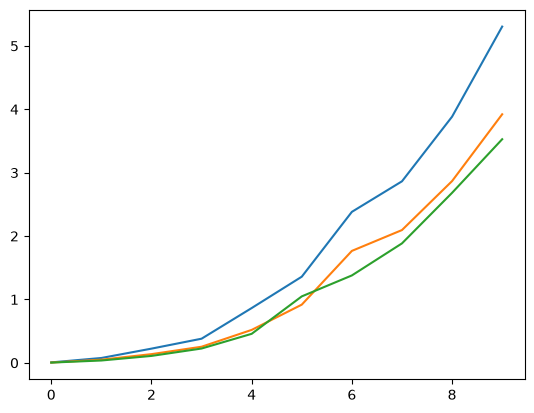

In [62]:
Time1 = np.array(Time1)
Time2 = np.array(Time2)
Time3 = np.array(Time3)

plt.plot(Time1)
plt.plot(Time2)
plt.plot(Time3)

# Compressed Shuffling

In [ ]:
def test(n=500):
    a = 0.5
    b = 1
    w = np.array([[b,b,a,a],[b,b,a,a],[a,a,b,b],[a,a,b,b]])
    A = RT.Aztec(n,w)
    C = A._RandomTiling__C
    E = A._RandomTiling__E
    M = cmpr_shuffling(C,E)[0]
    M = expand_blocks(M)
    A._RandomTiling__M = M
    A.plot(dpi=500)

In [3]:
# In the old matrix, each code occupies these cells of a 2 x 2 block:
# 0: none, 1: upper left, 2: upper right, 3: lower left,
# 4: lower right, 5: main diagonal, 6: other diagonal.
_TOP_LEFT = np.array([0, 1, 0, 0, 0, 1, 0], dtype=np.int8)
_TOP_RIGHT = np.array([0, 0, 1, 0, 0, 0, 1], dtype=np.int8)
_BOTTOM_LEFT = np.array([0, 0, 0, 1, 0, 0, 1], dtype=np.int8)
_BOTTOM_RIGHT = np.array([0, 0, 0, 0, 1, 1, 0], dtype=np.int8)

# Whether a block has an occupied cell on a given edge.
_HAS_LEFT = np.array([0, 1, 0, 1, 0, 1, 1], dtype=np.int8)
_HAS_RIGHT = np.array([0, 0, 1, 0, 1, 1, 1], dtype=np.int8)
_HAS_TOP = np.array([0, 1, 1, 0, 0, 1, 1], dtype=np.int8)
_HAS_BOTTOM = np.array([0, 0, 0, 1, 1, 1, 1], dtype=np.int8)


def DF(w, x, y, z):
    """Destroy and flip one new block from four old neighboring blocks."""
    a = _BOTTOM_RIGHT[w]
    b = _BOTTOM_LEFT[x]
    c = _TOP_RIGHT[y]
    d = _TOP_LEFT[z]
    if a + b + c + d != 1:
        return 0
    if a:
        return 4
    if b:
        return 3
    if c:
        return 2
    return 1


DF_Table = np.empty((7, 7, 7, 7), dtype=np.int8)
for _w in range(7):
    for _x in range(7):
        for _y in range(7):
            for _z in range(7):
                DF_Table[_w, _x, _y, _z] = DF(_w, _x, _y, _z)


@njit(cache=True)
def cmpr_shuffling(C0, E0):
    """Return the tiling as an N x N array of codes 0..6, plus overflow."""
    C = C0.copy()
    E = E0.copy()
    N = C.shape[0] // 2
    M0 = np.zeros((N, N), dtype=np.int8)
    M1 = np.zeros((N, N), dtype=np.int8)
    overflow = False

    A = N - 1
    w, x, y, z = C[A, A], C[A, A + 1], C[A + 1, A], C[A + 1, A + 1]
    ew, ex, ey, ez = E[A, A], E[A, A + 1], E[A + 1, A], E[A + 1, A + 1]
    prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
    overflow = overflow or of
    if N % 2 == 0:
        Mold = M1
    else:
        Mold = M0
    if np.random.random() < prob:
        Mold[0, 0] = 5
    else:
        Mold[0, 0] = 6

    # Each stage changes the parity of the block grid. Reuse two buffers.
    for k in range(1, N):
        if (k + N) % 2 == 0:
            Mnew = M1
        else:
            Mnew = M0
        A = N - 1 - k

        # Top-left corner.
        i = A
        j = A
        w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
        ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
        w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
        overflow = overflow or of
        C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
        E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
        Mnew[0, 0] = DF_Table[0, 0, 0, Mold[0, 0]]

        # Top row and left column in one loop.
        for t in range(1, k + 1):
            i = A
            j = A + 2 * t
            w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
            ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
            w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
            overflow = overflow or of
            C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
            E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
            Mnew[0, t] = DF_Table[0, 0, Mold[0, t - 1], Mold[0, t]]

            i = A + 2 * t
            j = A
            w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
            ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
            w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
            overflow = overflow or of
            C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
            E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
            Mnew[t, 0] = DF_Table[0, Mold[t - 1, 0], 0, Mold[t, 0]]

        # Remaining blocks. Mold's unused bottom row and right column are zero.
        for m in range(1, k + 1):
            i = A + 2 * m
            for n in range(1, k + 1):
                j = A + 2 * n
                w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
                ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
                w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
                overflow = overflow or of
                C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
                E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
                Mnew[m, n] = DF_Table[
                    Mold[m - 1, n - 1], Mold[m - 1, n],
                    Mold[m, n - 1], Mold[m, n]
                ]

        # Fill only holes with no occupied cell touching one of their sides.
        for m in range(k + 1):
            for n in range(k + 1):
                if Mnew[m, n] != 0:
                    continue
                if n > 0 and _HAS_RIGHT[Mnew[m, n - 1]]:
                    continue
                if n < k and _HAS_LEFT[Mnew[m, n + 1]]:
                    continue
                if m > 0 and _HAS_BOTTOM[Mnew[m - 1, n]]:
                    continue
                if m < k and _HAS_TOP[Mnew[m + 1, n]]:
                    continue

                i = A + 2 * m
                j = A + 2 * n
                w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
                ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
                prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
                overflow = overflow or of
                if np.random.random() < prob:
                    Mnew[m, n] = 5
                else:
                    Mnew[m, n] = 6

        Mold = Mnew

    return Mold, overflow


def expand_blocks(M):
    """Convert an N x N code array back to the old 2N x 2N binary array."""
    N = M.shape[0]
    out = np.empty((2 * N, 2 * N), dtype=np.int8)
    out[0::2, 0::2] = _TOP_LEFT[M]
    out[0::2, 1::2] = _TOP_RIGHT[M]
    out[1::2, 0::2] = _BOTTOM_LEFT[M]
    out[1::2, 1::2] = _BOTTOM_RIGHT[M]
    return out


In [4]:


# In the old matrix, each code occupies these cells of a 2 x 2 block:
# 0: none, 1: upper left, 2: upper right, 3: lower left,
# 4: lower right, 5: main diagonal, 6: other diagonal.
_TOP_LEFT = np.array([0, 1, 0, 0, 0, 1, 0], dtype=np.int8)
_TOP_RIGHT = np.array([0, 0, 1, 0, 0, 0, 1], dtype=np.int8)
_BOTTOM_LEFT = np.array([0, 0, 0, 1, 0, 0, 1], dtype=np.int8)
_BOTTOM_RIGHT = np.array([0, 0, 0, 0, 1, 1, 0], dtype=np.int8)

# Whether a block has an occupied cell on a given edge.
_HAS_LEFT = np.array([0, 1, 0, 1, 0, 1, 1], dtype=np.int8)
_HAS_RIGHT = np.array([0, 0, 1, 0, 1, 1, 1], dtype=np.int8)
_HAS_TOP = np.array([0, 1, 1, 0, 0, 1, 1], dtype=np.int8)
_HAS_BOTTOM = np.array([0, 0, 0, 1, 1, 1, 1], dtype=np.int8)


def DF(w, x, y, z):
    """Destroy and flip one new block from four old neighboring blocks."""
    a = _BOTTOM_RIGHT[w]
    b = _BOTTOM_LEFT[x]
    c = _TOP_RIGHT[y]
    d = _TOP_LEFT[z]
    if a + b + c + d != 1:
        return 0
    if a:
        return 4
    if b:
        return 3
    if c:
        return 2
    return 1


DF_Table = np.empty((7, 7, 7, 7), dtype=np.int8)
for _w in range(7):
    for _x in range(7):
        for _y in range(7):
            for _z in range(7):
                DF_Table[_w, _x, _y, _z] = DF(_w, _x, _y, _z)


#@njit(cache=True)
def cmpr_shuffling0(C0, E0):
    """Return the tiling as an N x N array of codes 0..6, plus overflow."""
    C = C0.copy()
    E = E0.copy()
    N = C.shape[0] // 2
    M0 = np.zeros((N, N), dtype=np.int8)
    M1 = np.zeros((N - 1, N - 1), dtype=np.int8)
    overflow = False

    T1 = 0
    T2 = 0
    T3 = 0

    A = N - 1
    w, x, y, z = C[A, A], C[A, A + 1], C[A + 1, A], C[A + 1, A + 1]
    ew, ex, ey, ez = E[A, A], E[A, A + 1], E[A + 1, A], E[A + 1, A + 1]
    prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
    overflow = overflow or of
    if N % 2 == 0:
        Mold = M1
    else:
        Mold = M0
    if np.random.random() < prob:
        Mold[0, 0] = 5
    else:
        Mold[0, 0] = 6

    # Each stage changes the parity of the block grid. Reuse two buffers.
    for k in range(1, N):
        if (k + N) % 2 == 0:
            Mnew = M1
        else:
            Mnew = M0
        A = N - 1 - k
        t1 = time()
        for m in range(k + 1):
            for n in range(k + 1):
                i = A + 2 * m
                j = A + 2 * n
                w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
                ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
                w, x, y, z, ew, ex, ey, ez, of = update(w, x, y, z, ew, ex, ey, ez)
                overflow = overflow or of
                C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1] = w, x, y, z
                E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1] = ew, ex, ey, ez
        T1 += time()-t1
        t1 = time()
        for m in range(k + 1):
            for n in range(k + 1):
                nw = Mold[m - 1, n - 1] if m and n else 0
                ne = Mold[m - 1, n] if m and n < k else 0
                sw = Mold[m, n - 1] if m < k and n else 0
                se = Mold[m, n] if m < k and n < k else 0
                Mnew[m, n] = DF_Table[nw, ne, sw, se]
        T2 += time()-t1
        t1 = time()
        # Fill only holes with no occupied cell touching one of their sides.
        for m in range(k + 1):
            for n in range(k + 1):
                if Mnew[m, n] != 0:
                    continue
                if n > 0 and _HAS_RIGHT[Mnew[m, n - 1]]:
                    continue
                if n < k and _HAS_LEFT[Mnew[m, n + 1]]:
                    continue
                if m > 0 and _HAS_BOTTOM[Mnew[m - 1, n]]:
                    continue
                if m < k and _HAS_TOP[Mnew[m + 1, n]]:
                    continue

                i = A + 2 * m
                j = A + 2 * n
                w, x, y, z = C[i, j], C[i, j + 1], C[i + 1, j], C[i + 1, j + 1]
                ew, ex, ey, ez = E[i, j], E[i, j + 1], E[i + 1, j], E[i + 1, j + 1]
                prob, of = comp_prop(w, x, y, z, ew, ex, ey, ez)
                overflow = overflow or of
                if np.random.random() < prob:
                    Mnew[m, n] = 5
                else:
                    Mnew[m, n] = 6
        T3 += time()-t1

        Mold = Mnew
    #print(T1)
    print(T2+T3)
    #print(T3)
    return Mold, overflow


def expand_blocks(M):
    """Convert an N x N code array back to the old 2N x 2N binary array."""
    N = M.shape[0]
    out = np.empty((2 * N, 2 * N), dtype=np.int8)
    out[0::2, 0::2] = _TOP_LEFT[M]
    out[0::2, 1::2] = _TOP_RIGHT[M]
    out[1::2, 0::2] = _BOTTOM_LEFT[M]
    out[1::2, 1::2] = _BOTTOM_RIGHT[M]
    return out


In [126]:
n = 300
reps = 1

a = 0.5
b = 1
w = np.array([[b,b,a,a],[b,b,a,a],[a,a,b,b],[a,a,b,b]])
A = RT.Aztec(n,w)
C = A._RandomTiling__C
E = A._RandomTiling__E

cmpr = 1

t1 = time()
for _ in range(reps):
    if cmpr:
        M = cmpr_shuffling0(C,E)[0]
        M = expand_blocks(M)
        A._RandomTiling__M = M
    else:
        A.shuffle()
print()
print((time()-t1)/reps)

#A.plot(dpi=500)


16.335947499930626
5.156868600024609
4.207049900025595

25.703256099994178


In [117]:
reps = 5
Time1 = []
Time2 = []

for n in trange(100,2100,100):
    A = RT.Aztec(n)
    C = A._RandomTiling__C
    E = A._RandomTiling__E

    collect()
    t1 = time()
    for _ in range(reps):
        A.shuffle()
    Time1+= [(time()-t1)/reps]

    collect()
    t1 = time()
    for _ in range(reps):
        M = cmpr_shuffling(C,E)[0]
        M = expand_blocks(M)
    Time2+= [(time()-t1)/reps]

100%|██████████| 20/20 [36:06<00:00, 108.31s/it]


In [118]:
Time1 = np.array(Time1)
Time2 = np.array(Time2)
Time1/Time2

array([1.3962662 , 2.17716972, 1.55747711, 1.31281725, 1.29917682,
       1.28285333, 1.23876603, 1.28108895, 1.2377273 , 1.24870004,
       1.24715883, 1.24026572, 1.25470027, 1.23976375, 1.24410392,
       1.23511366, 1.23302638, 1.25639364, 1.23698903, 1.27041464])

In [18]:
n = 100


A = RT.Aztec(n)
C = A._RandomTiling__C
E = A._RandomTiling__E

collect()
t1 = time()
shuffling0(C,E)
print(time()-t1)
print()

collect()
t1 = time()
M = cmpr_shuffling0(C,E)[0]
M = expand_blocks(M)
print(time()-t1)


1.0105195999894931
2.3030880999995134

0.7727768999884574
2.132414300000164


In [116]:
0.675/0.517

1.3056092843326887